In [34]:
import numpy as np
import h5py

In [35]:
data_dir = "/Users/BenDobbins/Desktop/Northwestern/Lab/fmri-semantic-decoding/semantic-decoding-ecog/SE_Processed/FIR/"
data_file = "SE_emptyTask_10_HG_all_data.mat"

In [36]:
# f = h5py.File(data_dir + data_file, 'r')

# refs = f['all_data'][()]          # (7, 2962) object array of h5py references
# n_trials = refs.shape[1]

# def to_str(ds):
#     return ''.join(chr(c) for c in ds[()].flatten())

# def cell_strings(ds):             # a MATLAB cell of chars
#     return [to_str(f[r]) for r in ds[()].flatten()]

# trial = 0
# hg     = f[refs[0, trial]][()]    # (115, n_timepoints), channels x time
# word   = cell_strings(f[refs[3, trial]])[0]
# fs     = f[refs[5, trial]][()].item()
# chans  = cell_strings(f[refs[6, trial]])

# print(n_trials, hg.shape, word, fs, chans[:5])


In [37]:
import scipy.io as sio
import mat73 
import os
 
def load_data( filepath):
        '''
        Load experiment data from specified file path(s). Assumes data has been processed into `all_data` format.
        '''
        try:
            if isinstance(filepath, str):
                filepath = [filepath]
            if isinstance(filepath, list):
                all_data_, expt_lengths_ = [], []
                for i, fp in enumerate(filepath):
                    print(f'Reading file {fp}...')
                    if os.path.isfile(fp):
                        try:
                            run_data = sio.loadmat(fp)['all_data']
                        except Exception as e:
                            print(f'Warning: {e}. Attempting to load .mat file with mat73...')
                            run_data = mat73.loadmat(fp)['all_data']
                           
                        all_data_.append(run_data)
                        expt_lengths_.append(len(run_data))
                        print(f'Run {i + 1}: Loaded {len(run_data)} trials from {os.path.basename(fp)}')
                    else:
                        print(f'Run {i + 1}: No data found')
                print(f'Total: Loaded {sum(expt_lengths_)} trials')
                # self.expt_lengths = expt_lengths_
 
                return all_data_
 
        except Exception as e:
            print(f'Error: {e}. Please ensure that all file path(s) specified are valid.')
            return None

data = np.array(load_data(data_dir + data_file)[0], dtype=object)
data

Reading file /Users/BenDobbins/Desktop/Northwestern/Lab/fmri-semantic-decoding/semantic-decoding-ecog/SE_Processed/FIR/SE_emptyTask_10_HG_all_data.mat...
Run 1: Loaded 2962 trials from SE_emptyTask_10_HG_all_data.mat
Total: Loaded 2962 trials


array([[array([[-0.17608008, -0.47125664, -0.3689177 , ...,  0.76137594,
                -0.13562793, -0.73162513],
               [-0.21065489, -0.45517998, -0.33929162, ...,  0.88077808,
                -0.1027355 , -0.75251792],
               [-0.23356898, -0.43701931, -0.31010586, ...,  0.97672669,
                -0.07828074, -0.76388908],
               ...,
               [-0.17770738, -0.48560253, -0.32845337, ...,  0.50544137,
                -0.40192066, -0.48267243],
               [-0.18813896, -0.50204389, -0.43607519, ...,  0.60135381,
                -0.38281377, -0.41009312],
               [-0.1969484 , -0.51659211, -0.51586094, ...,  0.72132625,
                -0.36264851, -0.34152268]], shape=(4541, 115))          ,
        array(1.), array(2.27), ..., None, array(2000.),
        list(['O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8', 'O9', 'O11', 'O12', 'O13', 'O14', 'AC1', 'AC12', 'Q1', 'Q2', 'Q3', 'Q12', 'M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9', 'M10', 'N1',

## Data Layout

First index is trial

0. Neural data (samples x channels)
1. Voice onset within epoch (probably incorrect, ignore)
2. Duration of epoch
3. Word
4. ?
5. Sample rate
6. Channels (channels x 1)

---

# Sanity check: is the epoching / HG extraction right?

**Logic.** Every trial here is *one heard word* cut out of continuous story audio, so the
epochs are ragged. From `preprocessing_full/save_data_by_freq.m` the epoch is

```
[ voice_onset - crop_start_bleed ,  voice_offset + crop_end_bleed ]     (both bleeds = 1 s)
```

so **word onset is always at t = +1.0 s into the epoch**, **word offset is always 1.0 s before
the end**, and the only thing that varies is the word itself (median ~0.2 s here). That gives
three ways to line trials up, and a preprocessing error shows up differently in each:

| alignment | how variable length is handled | what it tests |
|---|---|---|
| **onset-locked** | fixed window around `+1.0 s`; offsets smear out | onset response (auditory cortex should fire here) |
| **offset-locked** | fixed window around `len-1.0 s`; onsets smear out | offset / word-end response |
| **piecewise time-warp** | 1 s pre in real time, word interval resampled to the *median* word duration, 1 s post in real time | both edges sharp at once — the main figure |

**Two more things that matter for listening data:**

1. This is continuous speech, so the 1 s "baseline" before a word usually contains *other words*.
   Trials whose word is preceded by a real silent gap are pulled out separately (`gap_before`) —
   those are the ones that should show a textbook onset transient.
2. HG power is z-scored but still very heavy-tailed (a single artifact sample hits z > 200).
   A plain trial mean is dominated by a handful of trials, so everything below uses artifact-trial
   rejection + a **20% trimmed mean**.


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from scipy.stats import trim_mean, ttest_rel

# ---- epoching constants, from preprocessing_full/SE_preprocessing_full.m -------------------
CROP_PRE  = 1.0     # cfg.crop_start_bleed : seconds kept before word onset
CROP_POST = 1.0     # cfg.crop_end_bleed   : seconds kept after word offset

FS    = float(np.asarray(data[0, 5]).item())
CHANS = [str(c) for c in data[0, 6]]
NCH   = len(CHANS)
NTR   = data.shape[0]

def _word(x):
    return str(x[0]) if isinstance(x, (list, np.ndarray)) else str(x)

words    = np.array([_word(data[i, 3]) for i in range(NTR)])
epoch_s  = np.array([float(np.asarray(data[i, 2]).item()) for i in range(NTR)])   # epoch duration
nsamp    = np.array([np.shape(data[i, 0])[0] for i in range(NTR)])
word_dur = epoch_s - CROP_PRE - CROP_POST                                         # heard-word duration

print(f"{NTR} trials, {NCH} channels, fs = {FS:g} Hz")
print(f"epoch length  : {epoch_s.min():.2f} - {epoch_s.max():.2f} s "
      f"({nsamp.min()} - {nsamp.max()} samples)")
print(f"word duration : median {np.median(word_dur):.3f} s, "
      f"5-95% {np.percentile(word_dur, 5):.3f} - {np.percentile(word_dur, 95):.3f} s")

# epoch length must equal CROP_PRE + word + CROP_POST to the sample -- if this fails the
# constants above are wrong for this file.
resid = nsamp - (np.round(epoch_s * FS).astype(int) + 1)
assert np.all(np.abs(resid) <= 1), f"epoch length != duration*fs (residuals {np.unique(resid)})"
print("epoch length matches stored duration to <=1 sample")

2962 trials, 115 channels, fs = 2000 Hz
epoch length  : 2.02 - 6.67 s (4041 - 13341 samples)
word duration : median 0.200 s, 5-95% 0.080 - 0.530 s
epoch length matches stored duration to <=1 sample


In [39]:
# ---- inter-word gaps, from the word-annotation file the MATLAB pipeline consumed ----------
# Trials are consecutive story words, but a few get dropped at the recording edges, so match
# the .mat trials back onto the label rows by (word, duration). This doubles as a check that
# the epoch boundaries really came from these annotations.
import os

LABEL_FILE = os.path.join(data_dir, "..", "..", "data", "labels",
                          os.path.basename(data_file).split("_HG_")[0] + "_story_words.txt")
LABEL_FILE = os.path.normpath(LABEL_FILE)

gap_before = np.full(NTR, np.nan)
gap_after  = np.full(NTR, np.nan)

if os.path.isfile(LABEL_FILE):
    lab = np.genfromtxt(LABEL_FILE, dtype=None, delimiter="\t", encoding="utf-8",
                        names=("on", "off", "w"))
    l_on, l_off = lab["on"], lab["off"]
    l_w = np.array([str(x) for x in lab["w"]])

    j, match = 0, np.full(NTR, -1)
    for i in range(NTR):
        while j < len(l_w) and not (l_w[j] == words[i]
                                    and abs((l_off[j] - l_on[j]) - word_dur[i]) < 0.011):
            j += 1
        if j < len(l_w):
            match[i] = j
            j += 1
    ok = match >= 0
    print(f"matched {ok.sum()}/{NTR} trials to {len(l_w)} annotated words "
          f"({len(l_w) - ok.sum()} label rows unused -> trials dropped at recording bounds)")

    m = match[ok]
    gap_before[ok] = np.where(m > 0,          l_on[m] - l_off[np.maximum(m - 1, 0)], np.inf)
    gap_after[ok]  = np.where(m < len(l_w)-1, l_on[np.minimum(m + 1, len(l_w)-1)] - l_off[m], np.inf)
else:
    print(f"no label file at {LABEL_FILE} -- skipping the isolated-word subset")

finite = np.isfinite(gap_before)
if finite.any():
    for g in (0.2, 0.3, 0.5, 1.0):
        print(f"  trials preceded by >= {g:.1f} s of silence: {np.nansum(gap_before >= g)}")

matched 2962/2962 trials to 2968 annotated words (6 label rows unused -> trials dropped at recording bounds)
  trials preceded by >= 0.2 s of silence: 267
  trials preceded by >= 0.3 s of silence: 205
  trials preceded by >= 0.5 s of silence: 149
  trials preceded by >= 1.0 s of silence: 84


In [40]:
# ---- build the three aligned views --------------------------------------------------------
# Each trial is smoothed with a 20 ms boxcar, then linearly resampled onto a common grid.
# Windows stop 0.9 s from the anchor (not 1.0) to stay clear of the epoch edges.

BIN     = 0.020            # s per output sample
SMOOTH  = int(0.020 * FS)  # boxcar width in raw samples
WIN     = 0.90             # s of real time kept on each side
N_WARP  = 12               # bins the word interval is warped into

t_pre  = np.arange(-WIN, 0, BIN)                 # pre-onset, real time
t_post = np.arange(0, WIN + 1e-9, BIN)           # post-offset, real time
u_word = (np.arange(N_WARP) + 0.5) / N_WARP      # normalised position inside the word
t_on   = np.arange(-WIN,  WIN + 1e-9, BIN)       # onset-locked axis
t_off  = np.arange(-WIN,  WIN + 1e-9, BIN)       # offset-locked axis

MED_W = float(np.median(word_dur))
# pseudo-time axis for the warped view: word occupies [0, MED_W]
t_warp = np.r_[t_pre, u_word * MED_W, MED_W + t_post]

ONSET  = np.empty((NTR, len(t_on),   NCH), np.float32)   # aligned to word onset
OFFSET = np.empty((NTR, len(t_off),  NCH), np.float32)   # aligned to word offset
WARP   = np.empty((NTR, len(t_warp), NCH), np.float32)   # onset + offset both fixed

for i in range(NTR):
    X = uniform_filter1d(np.asarray(data[i, 0], np.float32), SMOOTH, axis=0, mode="nearest")
    n = X.shape[0]
    s_on, s_off = CROP_PRE * FS, (n - 1) - CROP_POST * FS   # sample index of onset / offset

    def take(sidx):
        sidx = np.clip(sidx, 0, n - 1)
        lo = np.floor(sidx).astype(int)
        hi = np.minimum(lo + 1, n - 1)
        f  = (sidx - lo)[:, None]
        return X[lo] * (1 - f) + X[hi] * f

    ONSET[i]  = take(s_on  + t_on  * FS)
    OFFSET[i] = take(s_off + t_off * FS)
    WARP[i]   = take(np.r_[s_on + t_pre * FS,
                           s_on + u_word * (s_off - s_on),
                           s_off + t_post * FS])
    if i % 500 == 0:
        print(f"  {i}/{NTR}", end="\r")

print(f"ONSET {ONSET.shape}  OFFSET {OFFSET.shape}  WARP {WARP.shape}   "
      f"({(ONSET.nbytes + OFFSET.nbytes + WARP.nbytes) / 1e6:.0f} MB)")

ONSET (2962, 91, 115)  OFFSET (2962, 91, 115)  WARP (2962, 103, 115)   (388 MB)


In [41]:
# ---- artifact trials, robust averaging, response index ------------------------------------
ART_Z = 20.0                       # a trial is dropped if any channel/sample exceeds this
trial_max = np.abs(WARP).max((1, 2))
CLEAN = trial_max < ART_Z
print(f"artifact rejection at |z| > {ART_Z:g}: keeping {CLEAN.sum()}/{NTR} trials "
      f"(worst trial reaches z = {trial_max.max():.0f})")

ISO_GAP = 0.30
ISO = CLEAN & (gap_before >= ISO_GAP)
print(f"isolated-word subset (>= {ISO_GAP:g} s silence before onset): {ISO.sum()} trials")

BASE   = (-0.5, -0.1)              # baseline window, relative to the anchor
POSTW  = (0.0, 0.4)                # response window, relative to word onset
SM_BIN = 3                         # extra smoothing, in output bins (~60 ms)

def trial_avg(A, mask, tax, trim=0.2, base=BASE):
    """20% trimmed mean over trials, lightly smoothed, baseline-subtracted per channel."""
    m = trim_mean(A[mask], trim, axis=0)
    m = uniform_filter1d(m, SM_BIN, axis=0, mode="nearest")
    return m - m[(tax >= base[0]) & (tax < base[1])].mean(0)

def response_t(A, mask, tax, base=BASE, post=POSTW, clip=ART_Z):
    """Paired t across trials: mean(post window) vs mean(baseline), per channel."""
    a = np.minimum(A[mask], clip)
    b = a[:, (tax >= base[0]) & (tax < base[1])].mean(1)
    p = a[:, (tax >= post[0]) & (tax < post[1])].mean(1)
    return ttest_rel(p, b, axis=0).statistic

t_all = response_t(ONSET, CLEAN, t_on)
t_iso = response_t(ONSET, ISO,   t_on) if ISO.sum() > 20 else np.full(NCH, np.nan)

rank = np.argsort(-np.abs(t_all))
print("\nmost onset-modulated channels (paired t, all clean trials):")
for k in rank[:12]:
    print(f"  {CHANS[k]:>5}  t = {t_all[k]:+6.1f}   (isolated-word t = {t_iso[k]:+5.1f})")

artifact rejection at |z| > 20: keeping 2469/2962 trials (worst trial reaches z = 250)
isolated-word subset (>= 0.3 s silence before onset): 166 trials

most onset-modulated channels (paired t, all clean trials):
     L3  t =   +5.7   (isolated-word t =  +6.1)
     L8  t =   +5.4   (isolated-word t =  +5.8)
     J5  t =   -4.9   (isolated-word t =  -1.9)
     L2  t =   +4.0   (isolated-word t =  +6.1)
     J6  t =   -4.0   (isolated-word t =  -1.0)
    J12  t =   -3.5   (isolated-word t =  -1.1)
     L1  t =   +3.4   (isolated-word t =  +1.2)
    C11  t =   +3.2   (isolated-word t =  +0.8)
     F7  t =   -2.5   (isolated-word t =  -0.9)
    W18  t =   -2.5   (isolated-word t =  +0.9)
    C12  t =   +2.1   (isolated-word t =  +1.3)
    J11  t =   -2.0   (isolated-word t =  -1.8)


### Figure 1 — every channel, word interval time-warped

Black dashed line = word onset, red dashed line = word offset; the grey band in between is the
time-warped word. Channels whose onset response passes |t| > 4 are marked with `*` and a bold
black label. If the preprocessing is right, the marked channels should be anatomically
sensible (a contiguous run on one or two temporal depths), and the response should start at the
black line — not before it, and not at an arbitrary offset.

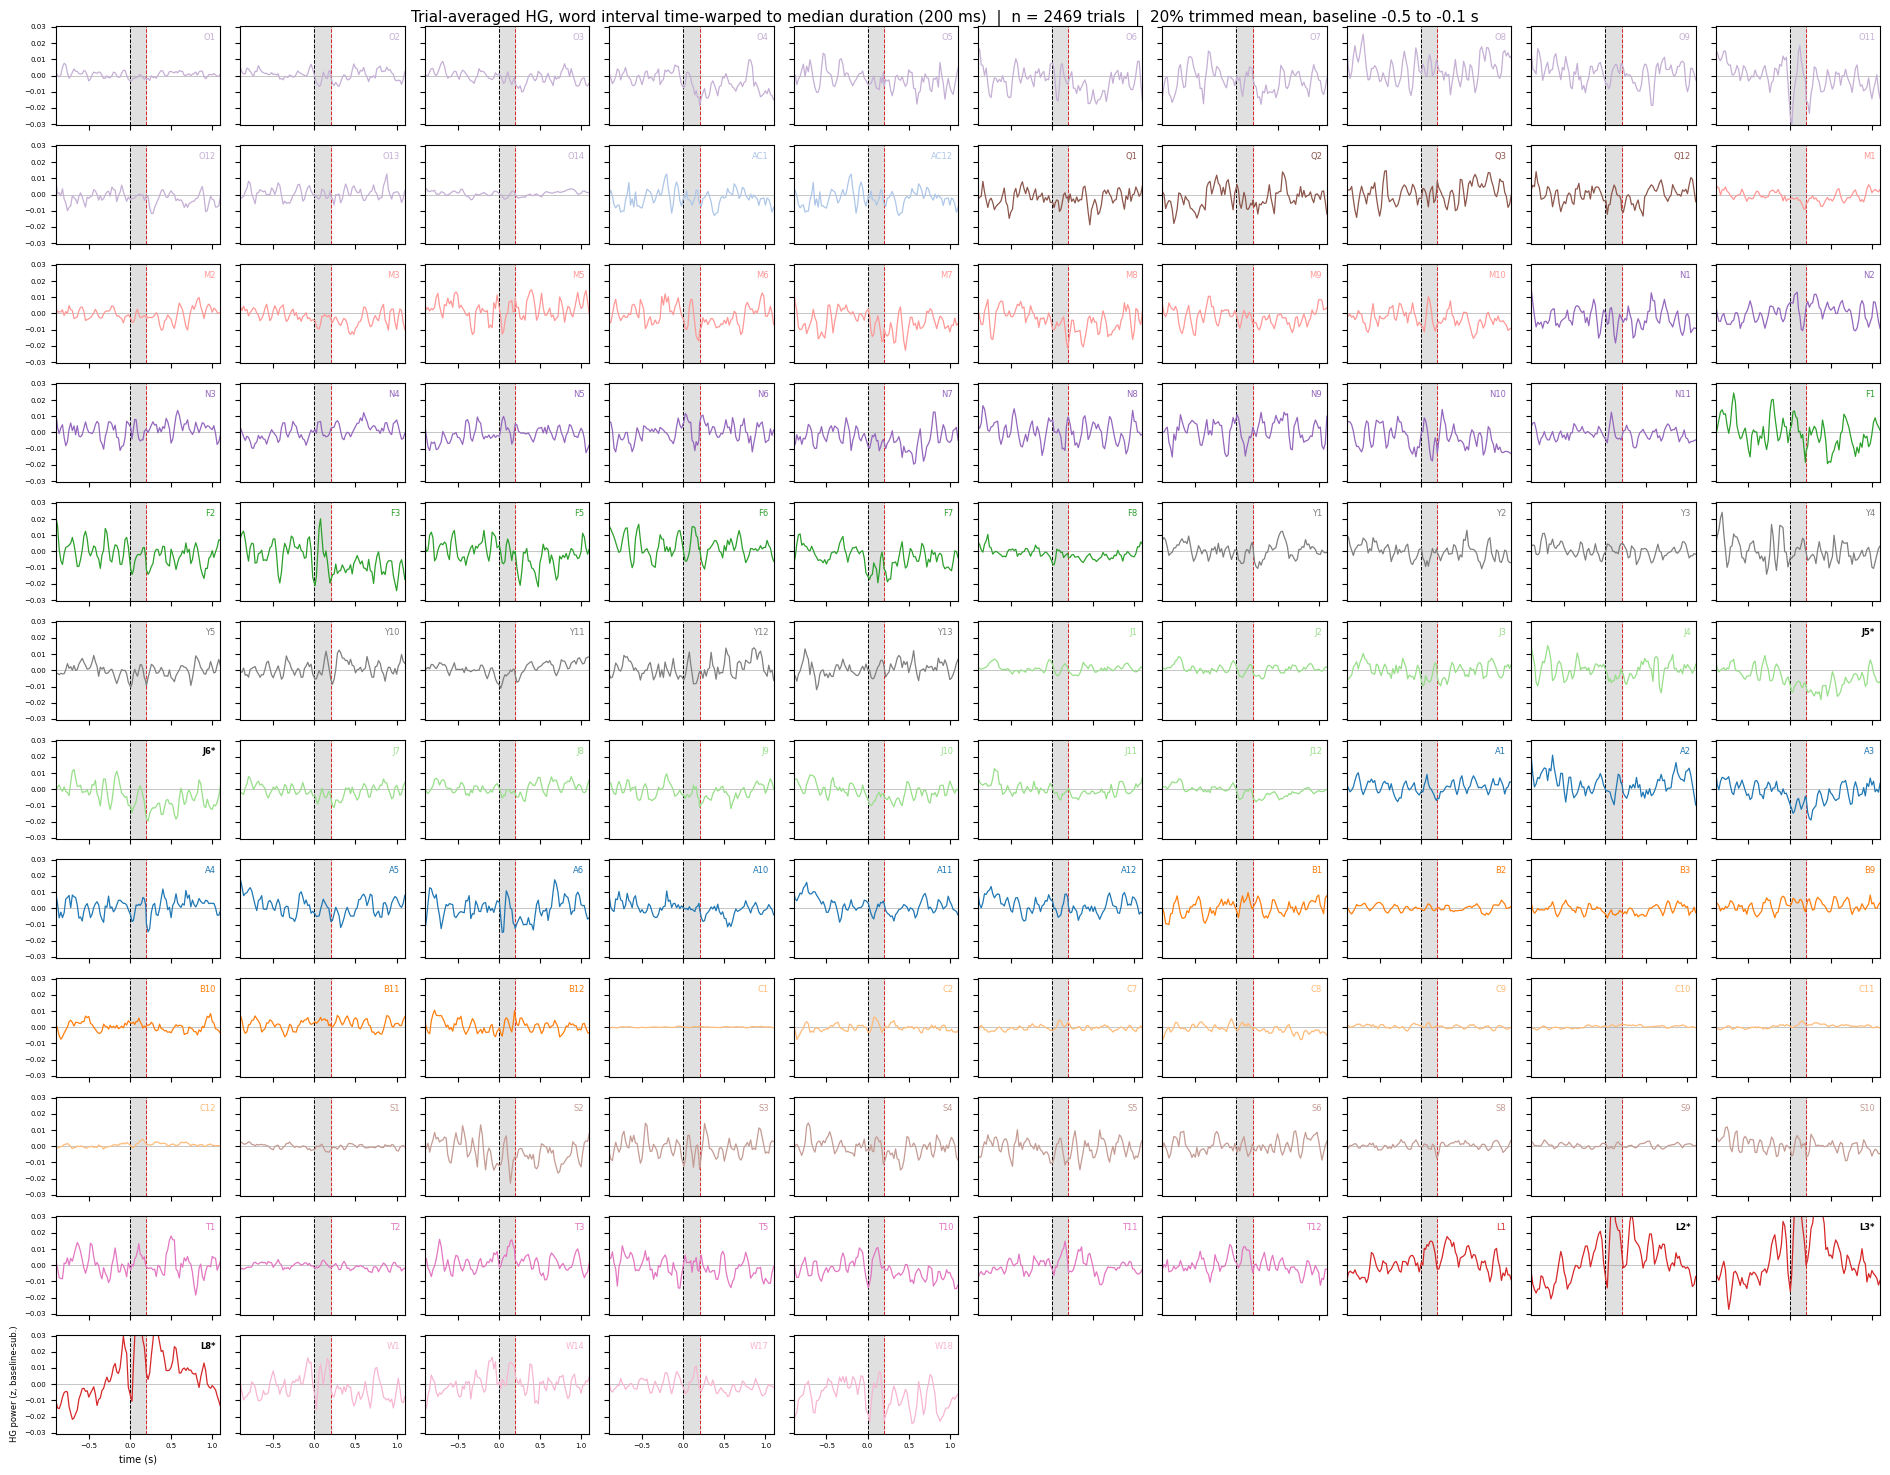

In [42]:
def channel_grid(M, tax, title, ncols=10, mark=None, mark_thresh=4.0,
                 word_span=(0.0, None), ylim=None):
    leads = [''.join(c for c in ch if c.isalpha()) for ch in CHANS]
    palette = plt.get_cmap("tab20")
    lead_col = {l: palette(i % 20) for i, l in enumerate(sorted(set(leads)))}

    nrows = int(np.ceil(NCH / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.9, nrows * 1.25),
                             sharex=True, sharey=True)
    if ylim is None:
        ylim = np.percentile(np.abs(M), 99.5) * 1.4
    w0, w1 = word_span

    for k, ax in enumerate(axes.ravel()):
        if k >= NCH:
            ax.axis("off")
            continue
        if w1 is not None:
            ax.axvspan(w0, w1, color="0.88", zorder=0)
            ax.axvline(w1, ls="--", lw=0.7, c="tab:red")
        ax.axvline(w0, ls="--", lw=0.7, c="k")
        ax.axhline(0, lw=0.4, c="0.6")
        ax.plot(tax, M[:, k], lw=0.9, c=lead_col[leads[k]])
        hit = mark is not None and np.isfinite(mark[k]) and abs(mark[k]) > mark_thresh
        ax.text(0.97, 0.93, CHANS[k] + ("*" if hit else ""), transform=ax.transAxes,
                ha="right", va="top", fontsize=6,
                color="k" if hit else lead_col[leads[k]],
                fontweight="bold" if hit else "normal")
        ax.tick_params(labelsize=5)

    axes.ravel()[0].set_ylim(-ylim, ylim)
    axes.ravel()[0].set_xlim(tax[0], tax[-1])
    axes[-1, 0].set_xlabel("time (s)", fontsize=7)
    axes[-1, 0].set_ylabel("HG power (z, baseline-sub.)", fontsize=6)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return fig

M = trial_avg(WARP, CLEAN, t_warp)
channel_grid(M, t_warp, mark=t_all, word_span=(0.0, MED_W),
             title=(f"Trial-averaged HG, word interval time-warped to median duration "
                    f"({MED_W*1000:.0f} ms)  |  n = {CLEAN.sum()} trials  |  "
                    f"20% trimmed mean, baseline {BASE[0]} to {BASE[1]} s"))
plt.show()

### Figure 2 — same grid, only words preceded by silence

Far fewer trials, so noisier, but the pre-onset baseline is genuinely quiet here. A real
auditory response should get **bigger**, not disappear. If a channel looks modulated in
Figure 1 but flat here, that "modulation" was probably driven by the surrounding speech
rather than by this word.

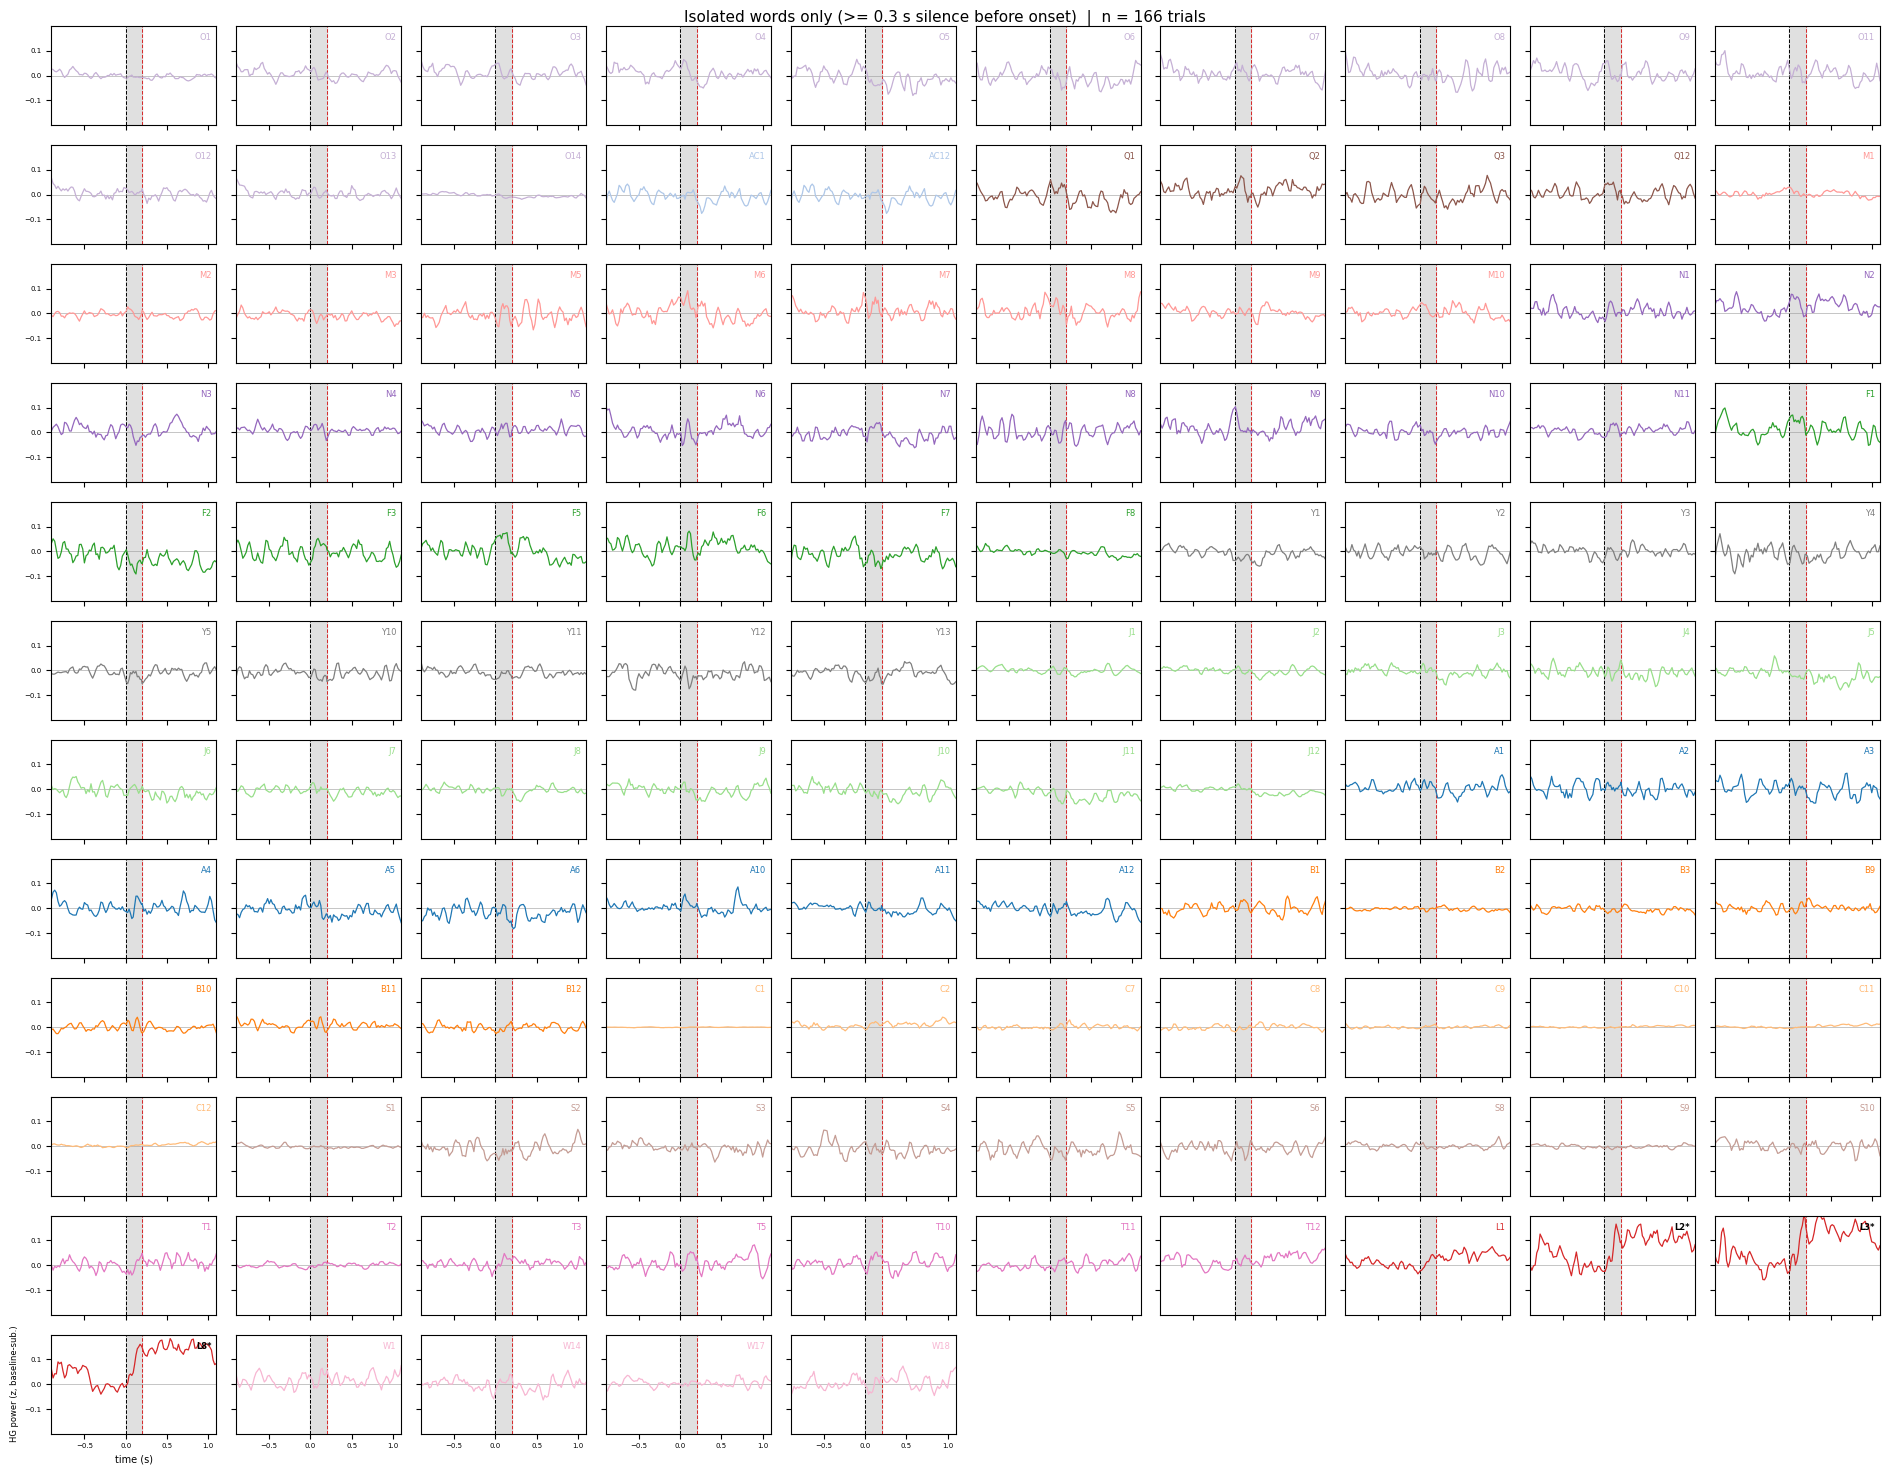

In [43]:
if ISO.sum() > 20:
    M_iso = trial_avg(WARP, ISO, t_warp)
    channel_grid(M_iso, t_warp, mark=t_iso, word_span=(0.0, MED_W),
                 title=(f"Isolated words only (>= {ISO_GAP:g} s silence before onset)  |  "
                        f"n = {ISO.sum()} trials"))
    plt.show()
else:
    print("not enough isolated-word trials to plot")

### Figure 3 — the three alignments side by side, for the most modulated channels

Onset-locked vs offset-locked vs warped. For a short-latency auditory channel the onset-locked
trace should be the sharpest; if instead the *offset*-locked trace is sharper, the epochs are
probably keyed to the wrong edge. A response that peaks *before* t = 0 in every alignment means
the epoch window is shifted (e.g. the FIR group-delay correction is off).

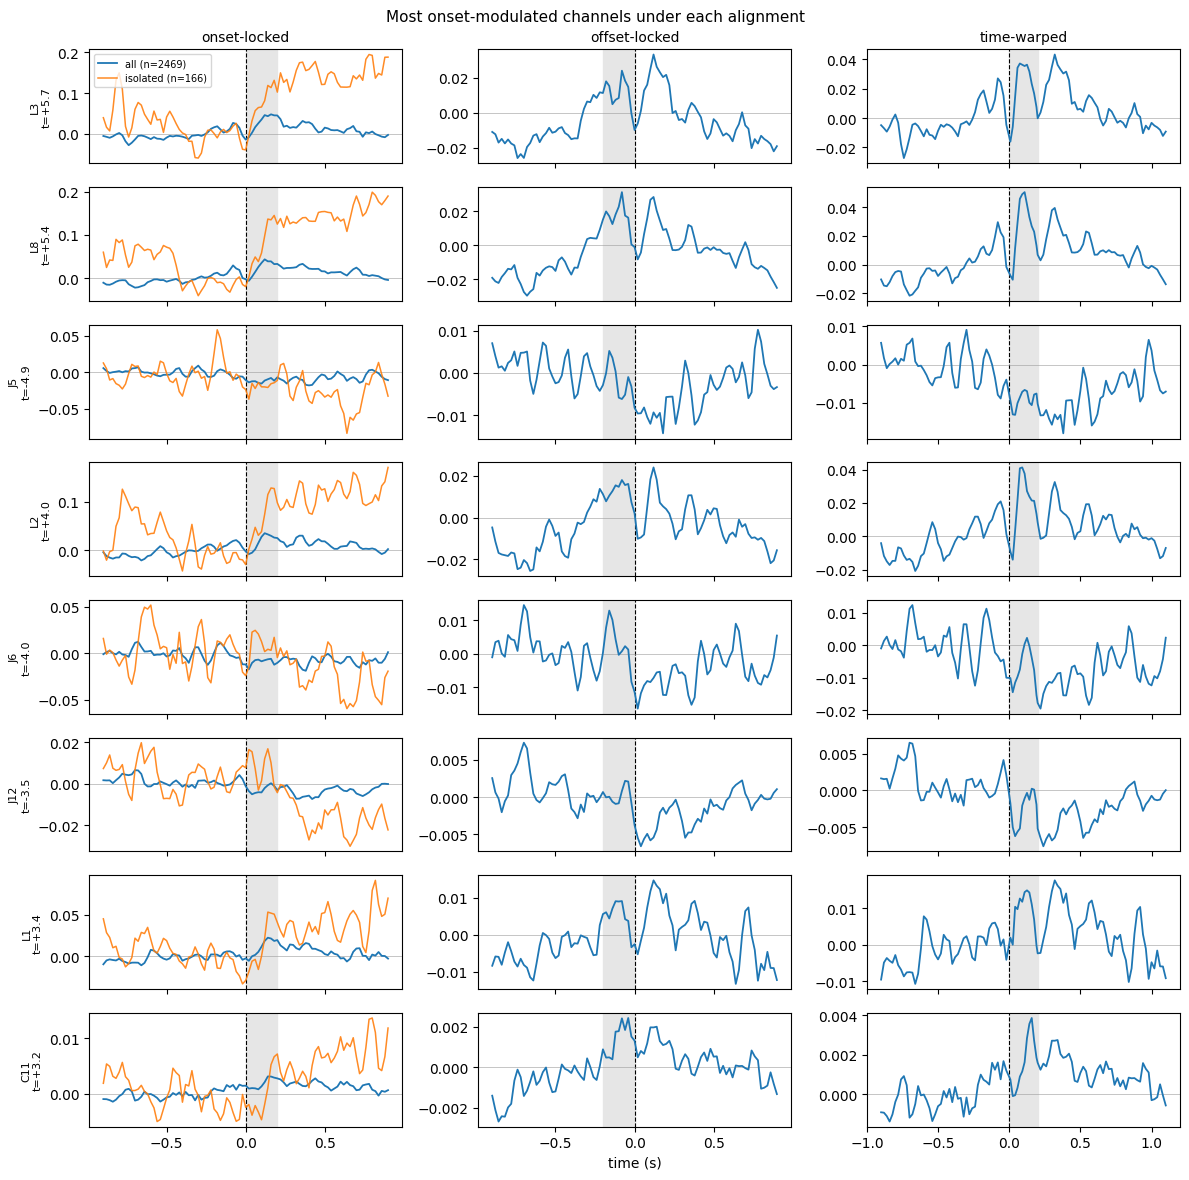

In [44]:
N_SHOW = 8
show = rank[:N_SHOW]

M_on   = trial_avg(ONSET,  CLEAN, t_on)
M_off  = trial_avg(OFFSET, CLEAN, t_off)
M_onI  = trial_avg(ONSET,  ISO,   t_on)  if ISO.sum() > 20 else None

fig, axes = plt.subplots(N_SHOW, 3, figsize=(12, 1.5 * N_SHOW), sharex="col")
for r, k in enumerate(show):
    for c, (lab, tax, M, span) in enumerate([
            ("onset-locked",  t_on,   M_on,  (0.0, MED_W)),
            ("offset-locked", t_off,  M_off, (-MED_W, 0.0)),
            ("time-warped",   t_warp, M,     (0.0, MED_W))]):
        ax = axes[r, c]
        ax.axvspan(*span, color="0.9", zorder=0)
        ax.axvline(span[0] if c != 1 else span[1], ls="--", lw=0.8, c="k")
        ax.axhline(0, lw=0.4, c="0.6")
        ax.plot(tax, M[:, k], lw=1.3, c="tab:blue",
                label=f"all (n={CLEAN.sum()})" if r == 0 else None)
        if c == 0 and M_onI is not None:
            ax.plot(t_on, M_onI[:, k], lw=1.1, c="tab:orange", alpha=0.9,
                    label=f"isolated (n={ISO.sum()})" if r == 0 else None)
        if r == 0:
            ax.set_title(lab, fontsize=10)
        if c == 0:
            ax.set_ylabel(f"{CHANS[k]}\nt={t_all[k]:+.1f}", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Most onset-modulated channels under each alignment", fontsize=11)
fig.tight_layout()
plt.show()

### Figure 4 — all channels as a heatmap, plus the diagnostics that don't need eyeballing

Left: channels sorted by onset t-statistic, so any real response collects at the top and the
rest of the array should look like noise. Right: how the response scales with word duration —
split the trials into duration terciles and check that, in the warped view, short and long words
give the *same* shape (that is what the warp is for), while in the onset-locked view the
long-word trace stays elevated longer.

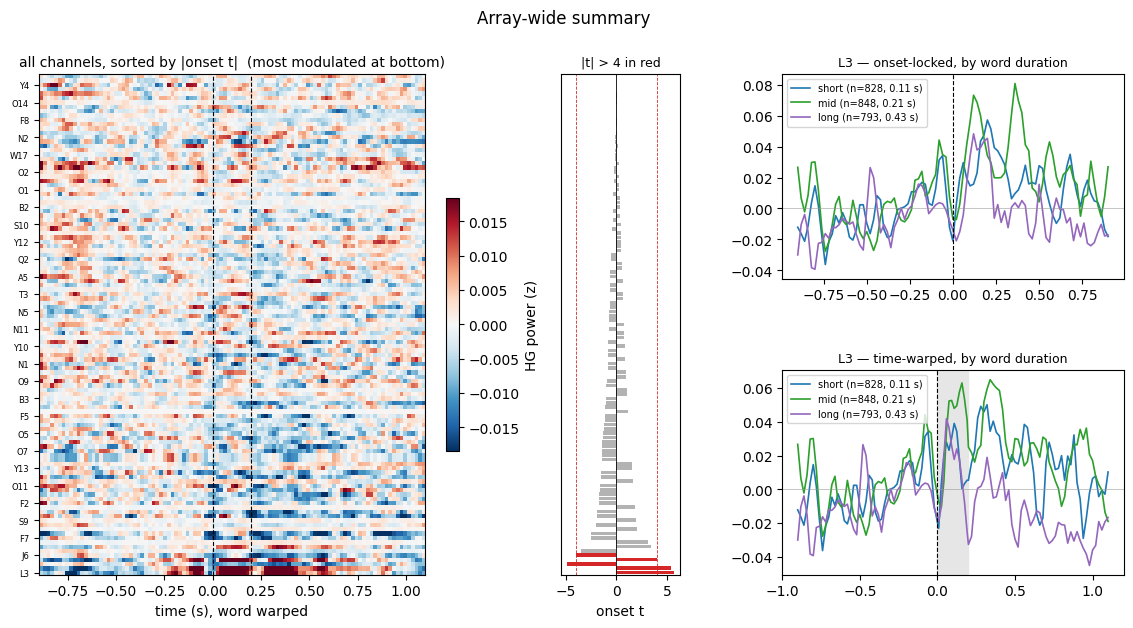

In [45]:
fig = plt.figure(figsize=(14, 6.5))
gs  = fig.add_gridspec(2, 3, width_ratios=[1.6, 0.45, 1.3], hspace=0.45, wspace=0.35)

# --- heatmap, channels sorted by onset t ---------------------------------------------------
axh = fig.add_subplot(gs[:, 0])
srt = rank
v   = np.percentile(np.abs(M), 99)
im  = axh.imshow(M[:, srt].T, aspect="auto", origin="lower", cmap="RdBu_r",
                 vmin=-v, vmax=v,
                 extent=[t_warp[0], t_warp[-1], -0.5, NCH - 0.5])
axh.axvline(0, ls="--", lw=0.8, c="k")
axh.axvline(MED_W, ls="--", lw=0.8, c="k")
axh.set_yticks(range(0, NCH, 4))
axh.set_yticklabels([CHANS[srt[i]] for i in range(0, NCH, 4)], fontsize=6)
axh.set_xlabel("time (s), word warped")
axh.set_title("all channels, sorted by |onset t|  (most modulated at bottom)", fontsize=10)
fig.colorbar(im, ax=axh, label="HG power (z)", fraction=0.03)

# --- t-statistic profile -------------------------------------------------------------------
axt = fig.add_subplot(gs[:, 1])
axt.barh(np.arange(NCH), t_all[srt], height=0.85,
         color=["tab:red" if abs(x) > 4 else "0.7" for x in t_all[srt]])
axt.axvline(0, lw=0.6, c="k")
for s in (-4, 4):
    axt.axvline(s, lw=0.6, ls="--", c="tab:red")
axt.set_ylim(-0.5, NCH - 0.5)
axt.set_yticks([])
axt.set_xlabel("onset t")
axt.set_title("|t| > 4 in red", fontsize=9)

# --- duration terciles -----------------------------------------------------------------------
q1, q2 = np.percentile(word_dur[CLEAN], [33, 67])
terciles = [("short", CLEAN & (word_dur <= q1)),
            ("mid",   CLEAN & (word_dur > q1) & (word_dur <= q2)),
            ("long",  CLEAN & (word_dur > q2))]
best = rank[0]

for row, (nm, tax, arr, span) in enumerate([
        ("onset-locked", t_on,   ONSET, None),
        ("time-warped",  t_warp, WARP,  (0.0, MED_W))]):
    ax = fig.add_subplot(gs[row, 2])
    for (lbl, msk), c in zip(terciles, ["tab:blue", "tab:green", "tab:purple"]):
        ax.plot(tax, trial_avg(arr, msk, tax)[:, best], lw=1.2, c=c,
                label=f"{lbl} (n={msk.sum()}, {word_dur[msk].mean():.2f} s)")
    if span:
        ax.axvspan(*span, color="0.9", zorder=0)
    ax.axvline(0, ls="--", lw=0.8, c="k")
    ax.axhline(0, lw=0.4, c="0.6")
    ax.set_title(f"{CHANS[best]} — {nm}, by word duration", fontsize=9)
    ax.legend(fontsize=7)
fig.suptitle("Array-wide summary", fontsize=12)
plt.show()

### What to conclude

- **Preprocessing looks right** if: a small, spatially contiguous set of channels shows a
  step up at the black onset line, that response is larger in the isolated-word subset, it is
  sharper onset-locked than offset-locked, and the warped traces for short/mid/long words
  superimpose.
- **Suspect a timing bug** if the response leads t = 0, or if the sharpest edge sits at the
  word offset instead — the FIR group-delay term (`fir_delay_s`) is added to the annotation
  times in `prepare_data.m` and is the usual culprit.
- **Suspect a channel-order bug** if the modulated channels are scattered across unrelated
  leads rather than clustered on one depth. Note the channel list in `all_data{:,7}` is built
  lead-by-lead after white-matter removal, so it is *not* the original recording order.
- Channels that are near-flat with occasional huge spikes (visible before artifact rejection)
  are the ones worth checking against the bad-channel list.